# 🗺️⚽ Raio-X Geográfico do Futebol Brasileiro

## 1. Contexto e Objetivo
Historicamente, o futebol brasileiro é dominado por equipes do eixo Sul-Sudeste. Mas será que essa força continua concentrada ou estamos vendo uma descentralização com o crescimento de clubes de outras regiões, como o Nordeste e o Centro-Oeste?

**Objetivos da Análise:**
1. Mapear o domínio histórico por estados e regiões (focando no Top 4 / Zona de Libertadores).
2. Analisar a evolução temporal para descobrir se novas regiões estão ganhando espaço na elite do futebol nacional.

**Fontes de Dados (Kaggle):**
* [Histórico do Campeonato Brasileiro (2003-2024)](https://www.kaggle.com/datasets/lucasyukioimafuko/brasileirao-serie-a-2006-2022)
* [Histórico de Partidas e média de público.](https://www.kaggle.com/datasets/rczekster/matches-brazilian-football-from-2003-to-2019)

## 2. Preparação e Cruzamento dos Dados
Nesta etapa, vamos importar os dados da classificação final (`df_brasileirao`) e os dados detalhados dos clubes (`df_times`), unindo-os para termos a visão geográfica completa de cada temporada.

In [ ]:
from google.colab import auth

try:
    auth.authenticate_user()
    print("Usuário autenticado com sucesso no Google Cloud!")
except Exception as e:
    print(f"[Erro de Autenticação]: {e}")

Usuário autenticado com sucesso no Google Cloud!


In [ ]:
from google.cloud import bigquery
import sys

client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_brazilian_league`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_brasileirao = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_partidas = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
import pandas as pd
df_partidas = pd.DataFrame(df_partidas)

df_partidas [['home_team_score', 'away_team_score']] = df_partidas['score'].str.split('x', expand=True)
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,07/10/2022,00:00,América Mineiro,1x2,São Paulo,1,2
1,22/07/2022,00:00,América Mineiro,0x1,Palmeiras,0,1
2,16/10/2022,00:30,América Mineiro,1x2,Fortaleza,1,2
3,04/09/2022,00:30,América Mineiro,2x0,Coritiba,2,0
4,22/05/2022,01:00,América Mineiro,1x1,Botafogo,1,1
...,...,...,...,...,...,...,...
9161,31/08/2025,22:30,Vitória,1x0,Atlético Mineiro,1,0
9162,25/05/2025,22:30,Vitória,0x1,Santos,0,1
9163,12/06/2025,23:00,Vitória,0x0,Cruzeiro,0,0
9164,02/10/2025,23:00,Vitória,1x0,Ceará,1,0


In [ ]:
colunas_placar = ['home_team_score', 'away_team_score']
df_partidas[colunas_placar] = df_partidas[colunas_placar].apply(pd.to_numeric, errors='coerce').astype(int)

In [ ]:
df_partidas['date'] = pd.to_datetime(df_partidas['date'], format='%d/%m/%Y')
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1
...,...,...,...,...,...,...,...
9161,2025-08-31,22:30,Vitória,1x0,Atlético Mineiro,1,0
9162,2025-05-25,22:30,Vitória,0x1,Santos,0,1
9163,2025-06-12,23:00,Vitória,0x0,Cruzeiro,0,0
9164,2025-10-02,23:00,Vitória,1x0,Ceará,1,0


In [ ]:
soma_gols = df_partidas['home_team_score'] + df_partidas['away_team_score']
df_partidas['total_gols'] = soma_gols
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2
...,...,...,...,...,...,...,...,...
9161,2025-08-31,22:30,Vitória,1x0,Atlético Mineiro,1,0,1
9162,2025-05-25,22:30,Vitória,0x1,Santos,0,1,1
9163,2025-06-12,23:00,Vitória,0x0,Cruzeiro,0,0,0
9164,2025-10-02,23:00,Vitória,1x0,Ceará,1,0,1


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_public_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_media_publico = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_teams`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_times = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
df_raiox_geografico = pd.merge(
    df_brasileirao,
    df_times,
    left_on= ['team'],
    right_on=['team'],
    how='inner'
)

print(df_raiox_geografico)
#df_raiox_geografico.head()

     season  place           team  points  played  won  draw  loss  goals  \
0      2022      1      Palmeiras      81      38   23    12     3     66   
1      2006      1      São Paulo      78      38   22    12     4     66   
2      2018      1      Palmeiras      80      38   23    11     4     64   
3      2019      1       Flamengo      90      38   28     6     4     86   
4      2022      2  Internacional      73      38   20    13     5     58   
..      ...    ...            ...     ...     ...  ...   ...   ...    ...   
433    2021     20    Chapecoense      15      38    1    12    25     27   
434    2004     24         Grêmio      39      46    9    12    25     60   
435    2005     21       Paysandu      41      42   12     5    25     63   
436    2013     20        Náutico      20      38    5     5    28     22   
437    2007     20     América-RN      17      38    4     5    29     24   

     goals_taken  goals_diff acronym                          full_name  \


## 3. Análise Parte 1: O Domínio do G4
Quantas vezes times de cada estado ou região terminaram o campeonato entre os 4 primeiros colocados? O eixo Rio-São Paulo é realmente o dono absoluto do topo da tabela?

In [ ]:
df_g4 = df_raiox_geografico[df_raiox_geografico['place'] <= 4]
contagem_g4 = df_g4['region'].value_counts()
print(contagem_g4)

region
Southeast    69
South        19
Northeast     2
Central       1
Name: count, dtype: int64


In [ ]:
df_g4 = df_raiox_geografico[df_raiox_geografico['place'] <= 4]
contagem_g4 = df_g4['state'].value_counts()
print(contagem_g4)

state
Sao Paulo            38
Rio de Janeiro       18
Rio Grande do Sul    17
Minas Gerais         13
Ceara                 2
Parana                2
Goias                 1
Name: count, dtype: int64


Qual região tem a maior rotatividade de times caindo e subindo? O rebaixamento é "democrático" ou castiga mais os times fora do eixo Sul-Sudeste?

In [ ]:
df_rebaixamento = df_raiox_geografico[df_raiox_geografico['place'] >= 17]
contagem_rebaixamento = df_rebaixamento['region'].value_counts()
print(contagem_rebaixamento)

region
South        31
Southeast    29
Northeast    19
Central      10
North         2
Name: count, dtype: int64


Quais estados têm o futebol mais "democrático" (com mais times diferentes chegando à elite) e quais são os maiores monopólios?

In [ ]:
df_diversidade = df_raiox_geografico.groupby(['state', 'season'])['team'].nunique().reset_index()
df_diversidade = df_diversidade.sort_values(by='team', ascending=False)

df_diversidade = df_diversidade.rename(columns={
    'state': 'Estado',
    'team': 'Qtd_Times_Diferentes'
})

print(df_diversidade)

             Estado  season  Qtd_Times_Diferentes
180       Sao Paulo    2004                     7
179       Sao Paulo    2003                     6
188       Sao Paulo    2012                     6
201       Sao Paulo    2025                     6
182       Sao Paulo    2006                     6
..              ...     ...                   ...
165  Santa Catarina    2009                     1
178  Santa Catarina    2024                     1
174  Santa Catarina    2018                     1
176  Santa Catarina    2021                     1
177  Santa Catarina    2022                     1

[202 rows x 3 columns]


## 4. Análise Parte 2: A Evolução Temporal
O campeonato está ficando mais equilibrado geograficamente? Vamos analisar a quantidade de pontos somados por cada região ao longo das temporadas.

In [ ]:
pontos_por_ano_regiao = df_raiox_geografico.groupby(['region', 'season'])['points'].sum().reset_index()
print(pontos_por_ano_regiao)

       region  season  points
0     Central    2003      65
1     Central    2004      72
2     Central    2005     115
3     Central    2006      55
4     Central    2007      45
..        ...     ...     ...
86  Southeast    2021     539
87  Southeast    2022     587
88  Southeast    2023     601
89  Southeast    2024     523
90  Southeast    2025     660

[91 rows x 3 columns]


Times pontuam mais quando jogam dentro da própria região (viagens curtas) do que quando cruzam o país (viagens longas)?

In [ ]:
import pandas as pd
import numpy as np

df_times_simples = df_times[['team', 'region']].copy()

df_raiox_jogos = pd.merge(
    df_partidas,
    df_times_simples,
    left_on= ['home_team'],
    right_on=['team'],
    how='left'
)

df_raiox_jogos = df_raiox_jogos.rename(columns={'region': 'regiao_mandante'})
df_raiox_jogos = df_raiox_jogos.drop(columns=['team'])

df_raiox_jogos = pd.merge(
    df_raiox_jogos,
    df_times_simples,
    left_on='away_team',
    right_on='team',
    how='left'
)

df_raiox_jogos = df_raiox_jogos.rename(columns={'region': 'regiao_visitante'})
df_raiox_jogos = df_raiox_jogos.drop(columns=['team'])


df_raiox_jogos['tipo_confronto'] = np.where(
    df_raiox_jogos['regiao_mandante'] == df_raiox_jogos['regiao_visitante'],
    'Regional (Mesma Região)',
    'Nacional (Regiões Diferentes)'
)

colunas_para_ver = ['home_team', 'regiao_mandante', 'away_team', 'regiao_visitante']
display(df_raiox_jogos[colunas_para_ver].head())

df_raiox_jogos['resultado_mandante'] = np.where(
    df_raiox_jogos['home_team_score'] > df_raiox_jogos['away_team_score'], 'Vitoria',
    np.where(
        df_raiox_jogos['home_team_score'] == df_raiox_jogos['away_team_score'], 'Empate', 'Derrota'
    )
)

analise_viagens = pd.crosstab(
    df_raiox_jogos['tipo_confronto'],
    df_raiox_jogos['resultado_mandante'],
    normalize='index'
) * 100

print("Taxa de Vitória do Mandante por Tipo de Confronto:")
print(analise_viagens[['Vitoria']].round(2))

,home_team,regiao_mandante,away_team,regiao_visitante
0,América Mineiro,Southeast,São Paulo,Southeast
1,América Mineiro,Southeast,Palmeiras,Southeast
2,América Mineiro,Southeast,Fortaleza,Northeast
3,América Mineiro,Southeast,Coritiba,South
4,América Mineiro,Southeast,Botafogo,Southeast


Taxa de Vitória do Mandante por Tipo de Confronto:
resultado_mandante             Vitoria
tipo_confronto                        
Nacional (Regiões Diferentes)    49.95
Regional (Mesma Região)          48.92


## 5. Conclusões e Insights Finais

**O Brasileirão é realmente um campeonato nacional ou apenas um torneio do Sudeste com convidados?** 🗺️⚽

Para o meu segundo projeto de portfólio em Ciência de Dados, decidi investigar a geografia do Campeonato Brasileiro na era dos pontos corridos. Cruzei dados históricos de partidas, rebaixamentos e classificações finais usando Python (Pandas) para testar os maiores mitos do nosso futebol.

Os resultados me surpreenderam bastante:

🏆 **1. A Elite tem dono (O Abismo do G4):**
Mito: "O futebol brasileiro está se descentralizando".
Realidade: O Sudeste é o dono absoluto do topo. Historicamente, times do Sudeste ocuparam o G4 em **69 ocasiões** (impulsionados por SP e RJ). Nordeste e Centro-Oeste somam apenas 3 aparições conjuntas na zona de Libertadores em toda a história dos pontos corridos.

📉 **2. A Gangorra do Rebaixamento pune o Sul:**
Apesar do Sudeste ter mais clubes disputando a Série A, é a região **Sul** que lidera o ranking de rebaixamentos, com **31 quedas**. Manter a regularidade na elite financeira e esportiva tem sido um desafio brutal para as equipes sulistas fora do eixo Athletico/Dupla Gre-Nal.

✈️ **3. O Mito das Longas Distâncias:**
Sempre ouvimos que viajar do Sul para o Nordeste destrói o time visitante. Fui testar isso nos dados e descobri que a taxa de vitória do mandante em confrontos nacionais (onde o visitante cruza o país) é de **49,95%**. Em clássicos regionais (viagens curtas), é de **48,92%**.
*Diferença de apenas 1%!* Atravessar o Brasil não torna o "Fator Casa" significativamente mais forte do que fazer uma viagem curta.

📊 Gráfico 1: O Domínio do G4 (Sudeste no Topo)

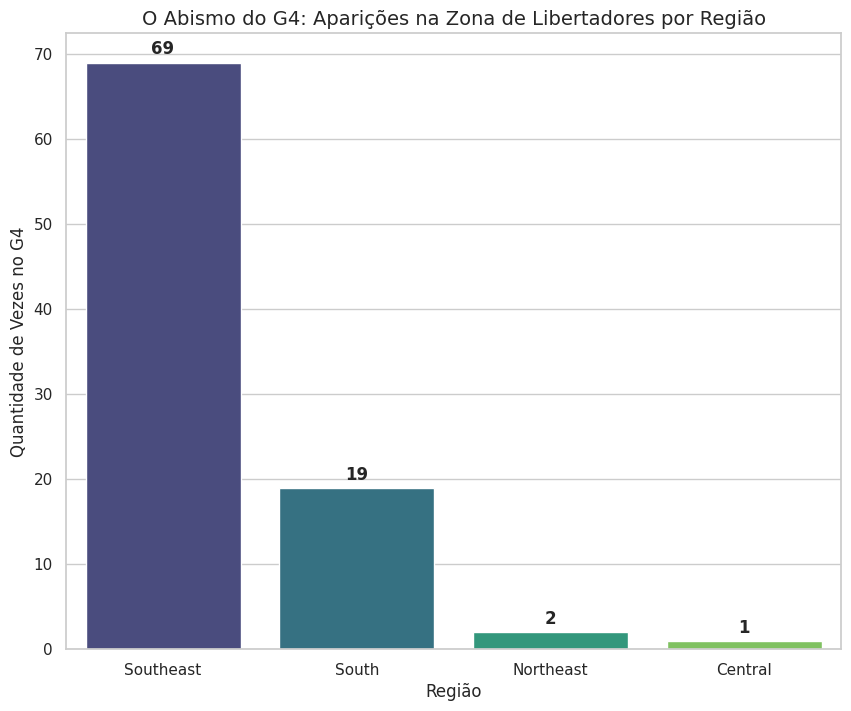

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_g4 = df_raiox_geografico[df_raiox_geografico['place'] <= 4]
g4_regiao = df_g4['region'].value_counts().reset_index()
g4_regiao.columns = ['Região', 'Aparições no G4']

plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=g4_regiao,
    x='Região',
    y='Aparições no G4',
    hue='Região',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=12, fontweight='bold')

plt.title('O Abismo do G4: Aparições na Zona de Libertadores por Região', fontsize=14)
plt.ylabel('Quantidade de Vezes no G4')
plt.xlabel('Região')
plt.savefig('04_dominio_g4_regiao.png', dpi=150, bbox_inches='tight')
plt.show()

📉 Gráfico 2: A Gangorra do Rebaixamento

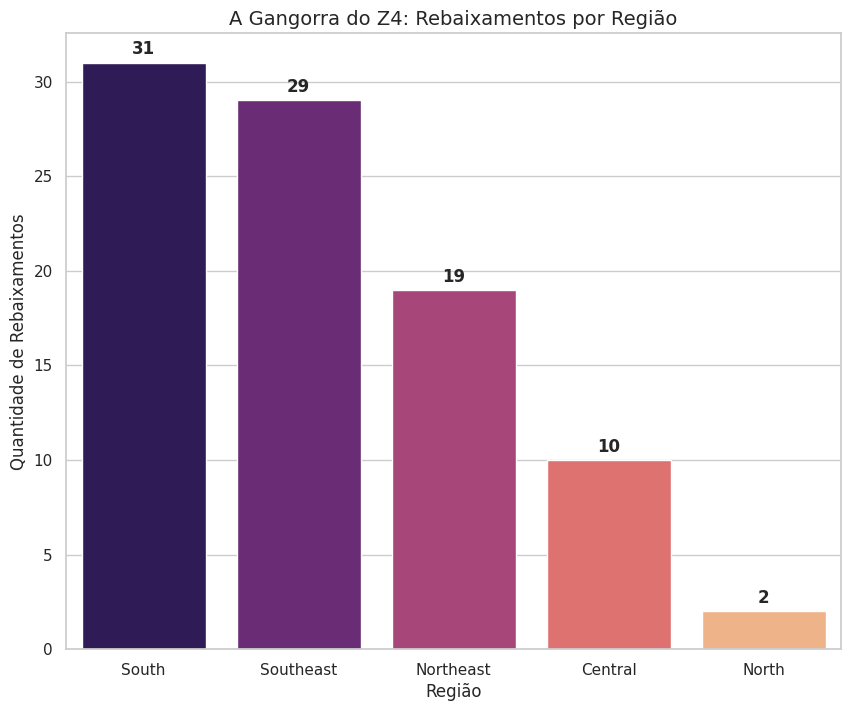

In [ ]:
df_z4 = df_raiox_geografico[df_raiox_geografico['place'] >= 17]
z4_regiao = df_z4['region'].value_counts().reset_index()
z4_regiao.columns = ['Região', 'Rebaixamentos']

plt.figure(figsize=(10, 8))

ax = sns.barplot(
    data=z4_regiao,
    x='Região',
    y='Rebaixamentos',
    hue='Região',
    palette='magma',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=12, fontweight='bold')

plt.title('A Gangorra do Z4: Rebaixamentos por Região', fontsize=14)
plt.ylabel('Quantidade de Rebaixamentos')
plt.xlabel('Região')
plt.savefig('gangorra_do_rebaixamento.png', dpi=150, bbox_inches='tight')
plt.show()

🏛️ Gráfico 3: Democracia vs Monopólio Estadual

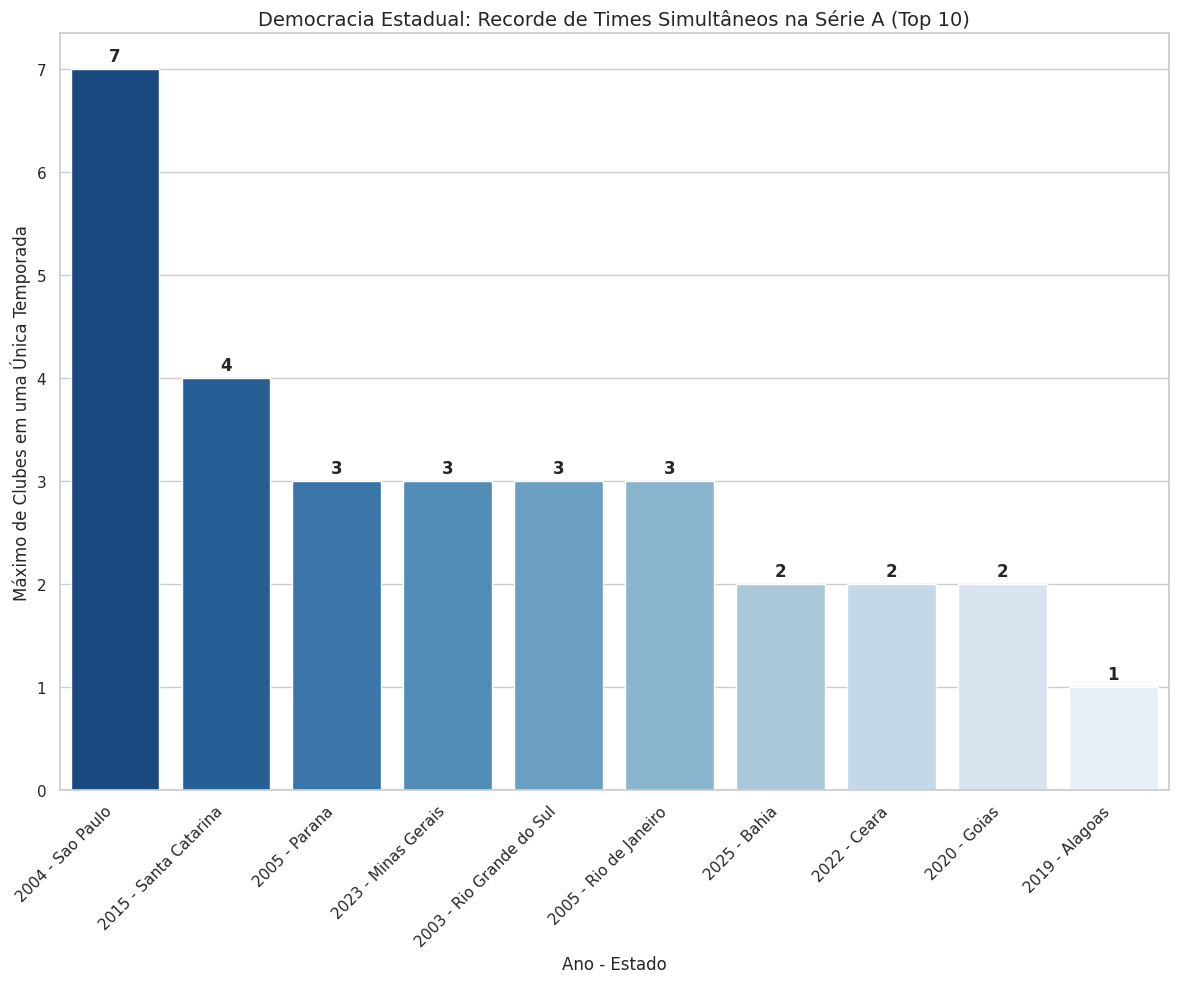

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_diversidade = df_raiox_geografico.groupby(['state', 'season'])['team'].nunique().reset_index()

df_diversidade = df_diversidade.sort_values(by='team', ascending=False)

df_recorde = df_diversidade.drop_duplicates(subset=['state'], keep='first').copy()

df_recorde.columns = ['Estado', 'Ano', 'Qtd_Times_Max']
df_recorde = df_recorde.sort_values(by='Qtd_Times_Max', ascending=False).head(10)

df_recorde['Ano_Estado'] = df_recorde['Ano'].astype(str) + ' - ' + df_recorde['Estado']

plt.figure(figsize=(12, 10))

ax = sns.barplot(
    data=df_recorde,
    x='Ano_Estado',
    y='Qtd_Times_Max',
    hue='Ano_Estado',
    palette='Blues_r',
    legend=False,
    dodge=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=12, fontweight='bold')


plt.ylim(0, df_recorde['Qtd_Times_Max'].max() * 1.05)

plt.title('Democracia Estadual: Recorde de Times Simultâneos na Série A (Top 10)', fontsize=14)
plt.ylabel('Máximo de Clubes em uma Única Temporada')
plt.xlabel('Ano - Estado')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('democracia_por_estadual.png', dpi=150, bbox_inches='tight')
plt.show()

✈️ Gráfico 4: O Mito das Distâncias

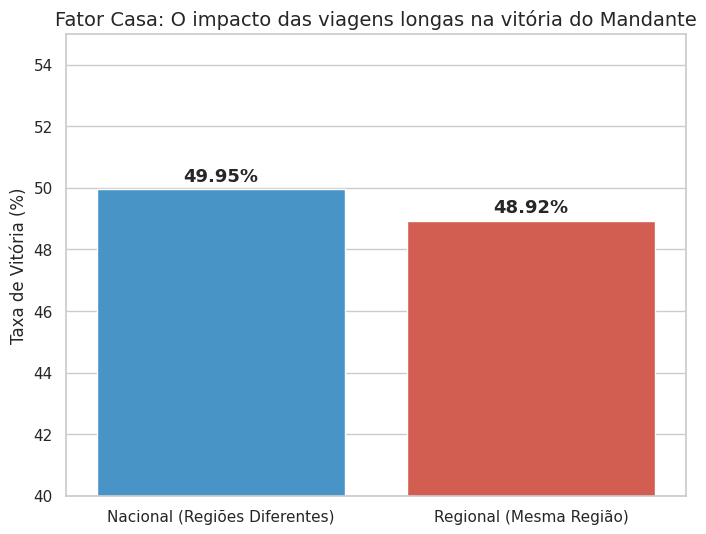

In [ ]:
df_viagens = analise_viagens[['Vitoria']].reset_index()
df_viagens.columns = ['Tipo de Confronto', 'Taxa_Vitoria_Mandante']

plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=df_viagens,
    x='Tipo de Confronto',
    y='Taxa_Vitoria_Mandante',
    hue='Tipo de Confronto',
    palette=['#3498db', '#e74c3c'],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=13, fontweight='bold')

plt.ylim(40, 55)

plt.title('Fator Casa: O impacto das viagens longas na vitória do Mandante', fontsize=14)
plt.ylabel('Taxa de Vitória (%)')
plt.xlabel('')
plt.savefig('impacto_de_viagens.png', dpi=150, bbox_inches='tight')
plt.show()